In [3]:
import torch
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import pandas as pd
import random
import math
import time

from pathlib import Path

# Reproducibility
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.0+cpu
Device: cpu


In [4]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Flatten each image: [N, 1, 28, 28] -> [N, 784]
X_train = train_dataset.data.float().view(-1, 784) / 255.0
y_train = train_dataset.targets.long()

X_test = test_dataset.data.float().view(-1, 784) / 255.0
y_test = test_dataset.targets.long()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

print("Minimum pixel value:", X_train.min().item())
print("Maximum pixel value:", X_train.max().item())

Training images: torch.Size([60000, 784])
Training labels: torch.Size([60000])
Testing images: torch.Size([10000, 784])
Testing labels: torch.Size([10000])
Minimum pixel value: 0.0
Maximum pixel value: 1.0


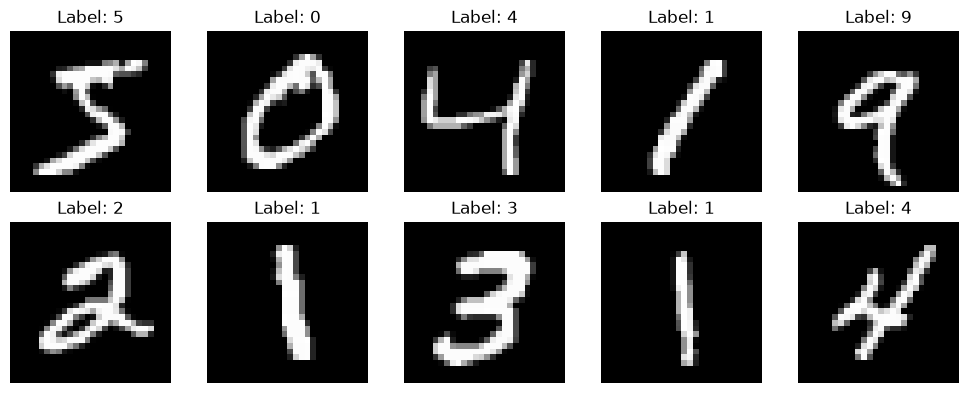

In [5]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {y_train[i].item()}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
def activate(z, name):
    if name == "relu":
        return torch.clamp(z, min=0)

    elif name == "sigmoid":
        return torch.sigmoid(z)

    elif name == "tanh":
        return torch.tanh(z)

    elif name == "leaky_relu":
        return torch.where(z > 0, z, 0.01 * z)

    else:
        raise ValueError("Unknown activation: " + name)


def activation_derivative(z, a, name):
    if name == "relu":
        return (z > 0).float()

    elif name == "sigmoid":
        return a * (1 - a)

    elif name == "tanh":
        return 1 - a**2

    elif name == "leaky_relu":
        return torch.where(
            z > 0,
            torch.ones_like(z),
            torch.full_like(z, 0.01)
        )

    else:
        raise ValueError("Unknown activation: " + name)

In [7]:
class ManualMLP:

    def __init__(self, sizes, activation="relu", seed=42):
        self.sizes = sizes
        self.activation = activation

        generator = torch.Generator().manual_seed(seed)

        self.W = []
        self.b = []

        # Initialize every layer's weights and biases.
        for fan_in, fan_out in zip(sizes[:-1], sizes[1:]):

            if activation in ("relu", "leaky_relu"):
                scale = math.sqrt(2.0 / fan_in)  # He initialization
            else:
                scale = math.sqrt(1.0 / fan_in)  # Xavier-like initialization

            weight = torch.randn(
                fan_in, fan_out, generator=generator
            ) * scale

            bias = torch.zeros(fan_out)

            self.W.append(
                weight.to(device).requires_grad_(False)
            )
            self.b.append(
                bias.to(device).requires_grad_(False)
            )

        self.zero_grad()

    def zero_grad(self):
        # Our gradients are ordinary tensors, not autograd gradients.
        self.dW = [torch.zeros_like(w) for w in self.W]
        self.db = [torch.zeros_like(b) for b in self.b]

    def forward(self, x):
        activations = [x]
        preactivations = []
        h = x

        # Hidden layers
        for i in range(len(self.W) - 1):
            z = h @ self.W[i] + self.b[i]
            a = activate(z, self.activation)

            preactivations.append(z)
            activations.append(a)
            h = a

        # Output layer produces logits, not probabilities.
        logits = h @ self.W[-1] + self.b[-1]

        preactivations.append(logits)
        activations.append(logits)

        return logits, activations, preactivations

    @staticmethod
    def loss_fn(logits, targets):
        # Stable softmax cross-entropy.
        log_probs = F.log_softmax(logits, dim=1)

        correct_log_probs = log_probs[
            torch.arange(len(targets), device=targets.device),
            targets
        ]

        return -correct_log_probs.mean()

    def backward(self, targets, activations, preactivations):
        batch_size = len(targets)

        # Output gradient: (probabilities - one-hot targets) / batch size
        probs = torch.softmax(preactivations[-1], dim=1)

        probs = probs.clone()
        probs[
            torch.arange(batch_size, device=targets.device),
            targets
        ] -= 1.0

        delta = probs / batch_size

        # Output layer gradients
        last = len(self.W) - 1

        self.dW[last] = activations[-2].T @ delta
        self.db[last] = delta.sum(dim=0)

        # Propagate error backward through the hidden layers.
        delta = delta @ self.W[last].T

        for i in range(last - 1, -1, -1):

            z = preactivations[i]
            a = activations[i + 1]

            delta = delta * activation_derivative(
                z, a, self.activation
            )

            self.dW[i] = activations[i].T @ delta
            self.db[i] = delta.sum(dim=0)

            if i > 0:
                delta = delta @ self.W[i].T

    def step(self, learning_rate):
        # Manual stochastic gradient descent.
        with torch.no_grad():
            for i in range(len(self.W)):
                self.W[i] -= learning_rate * self.dW[i]
                self.b[i] -= learning_rate * self.db[i]

    def predict(self, x, batch_size=1024):
        predictions = []

        with torch.no_grad():
            for start in range(0, len(x), batch_size):
                xb = x[start:start + batch_size].to(device)
                logits, _, _ = self.forward(xb)
                predictions.append(logits.argmax(dim=1).cpu())

        return torch.cat(predictions)

    def accuracy(self, x, y):
        predictions = self.predict(x)
        return (predictions == y.cpu()).float().mean().item() * 100

In [8]:
def train_model(
    X_train, y_train, X_test, y_test,
    sizes=(784, 256, 128, 10),
    activation="relu",
    learning_rate=0.05,
    batch_size=128,
    epochs=10,
    seed=42,
    noisy_fraction=0.0,
    noise_std=0.3,
    rotation_augmentation=False,
    run_name="Model"
):
    torch.manual_seed(seed)

    model = ManualMLP(sizes, activation, seed)
    n = len(X_train)

    # Choose which training images will receive Gaussian noise.
    noisy_mask = torch.zeros(n, dtype=torch.bool)
    noisy_count = int(n * noisy_fraction)

    if noisy_count > 0:
        noisy_mask[torch.randperm(n)[:noisy_count]] = True

    history = {
        "loss": [],
        "test_accuracy": [],
        "train_accuracy": [],
        "epochs_to_95": None
    }

    start_time = time.time()

    for epoch in range(1, epochs + 1):

        # Shuffle training examples each epoch.
        order = torch.randperm(n)

        total_loss = 0.0
        total_seen = 0

        for start in range(0, n, batch_size):

            ids = order[start:start + batch_size]

            xb = X_train[ids].clone().to(device)
            yb = y_train[ids].to(device)

            # Mission 4: noise only on the selected training images.
            selected = noisy_mask[ids]

            if selected.any():
                noise = torch.randn_like(xb[selected]) * noise_std
                xb[selected] = (xb[selected] + noise).clamp(0, 1)

            # Optional robustness defence: rotate training images.
            if rotation_augmentation:
                images = xb.view(-1, 1, 28, 28)
                rotated = []

                for image in images:
                    angle = random.uniform(-15, 15)

                    rotated.append(
                        transforms.functional.rotate(
                            image,
                            angle,
                            interpolation=transforms.InterpolationMode.BILINEAR
                        )
                    )

                xb = torch.stack(rotated).view(-1, 784)

            # 1. Forward propagation
            logits, activations, preactivations = model.forward(xb)

            # 2. Calculate loss
            loss = model.loss_fn(logits, yb)

            # 3. Backpropagation using our own formulas
            model.zero_grad()
            model.backward(yb, activations, preactivations)

            # 4. Update weights and biases
            model.step(learning_rate)

            total_loss += loss.item() * len(ids)
            total_seen += len(ids)

        # Average loss across all training examples.
        epoch_loss = total_loss / total_seen

        # Measure accuracy after the epoch.
        test_acc = model.accuracy(X_test, y_test)

        # Use a subset for faster training-accuracy reporting.
        subset = min(5000, len(X_train))
        train_acc = model.accuracy(
            X_train[:subset], y_train[:subset]
        )

        history["loss"].append(epoch_loss)
        history["test_accuracy"].append(test_acc)
        history["train_accuracy"].append(train_acc)

        if test_acc >= 95 and history["epochs_to_95"] is None:
            history["epochs_to_95"] = epoch

        print(
            f"{run_name} | Epoch {epoch:02d}/{epochs} | "
            f"Loss: {epoch_loss:.4f} | "
            f"Train Accuracy: {train_acc:.2f}% | "
            f"Test Accuracy: {test_acc:.2f}%"
        )

    history["seconds"] = time.time() - start_time
    history["final_test_accuracy"] = history["test_accuracy"][-1]

    return model, history

In [9]:
mission1_model, mission1_history = train_model(
    X_train, y_train, X_test, y_test,
    sizes=(784, 256, 128, 10),
    activation="relu",
    learning_rate=0.05,
    batch_size=128,
    epochs=10,
    seed=42,
    run_name="Mission 1"
)

print("\nFinal test accuracy:",
      f"{mission1_history['final_test_accuracy']:.2f}%")


Mission 1 | Epoch 01/10 | Loss: 0.4916 | Train Accuracy: 93.00% | Test Accuracy: 92.26%
Mission 1 | Epoch 02/10 | Loss: 0.2478 | Train Accuracy: 94.72% | Test Accuracy: 93.61%
Mission 1 | Epoch 03/10 | Loss: 0.1965 | Train Accuracy: 95.92% | Test Accuracy: 94.90%
Mission 1 | Epoch 04/10 | Loss: 0.1641 | Train Accuracy: 96.46% | Test Accuracy: 95.47%
Mission 1 | Epoch 05/10 | Loss: 0.1406 | Train Accuracy: 96.58% | Test Accuracy: 95.88%
Mission 1 | Epoch 06/10 | Loss: 0.1234 | Train Accuracy: 97.30% | Test Accuracy: 96.49%
Mission 1 | Epoch 07/10 | Loss: 0.1100 | Train Accuracy: 97.52% | Test Accuracy: 96.52%
Mission 1 | Epoch 08/10 | Loss: 0.0981 | Train Accuracy: 97.90% | Test Accuracy: 96.74%
Mission 1 | Epoch 09/10 | Loss: 0.0882 | Train Accuracy: 97.96% | Test Accuracy: 96.86%
Mission 1 | Epoch 10/10 | Loss: 0.0807 | Train Accuracy: 98.12% | Test Accuracy: 96.81%

Final test accuracy: 96.81%


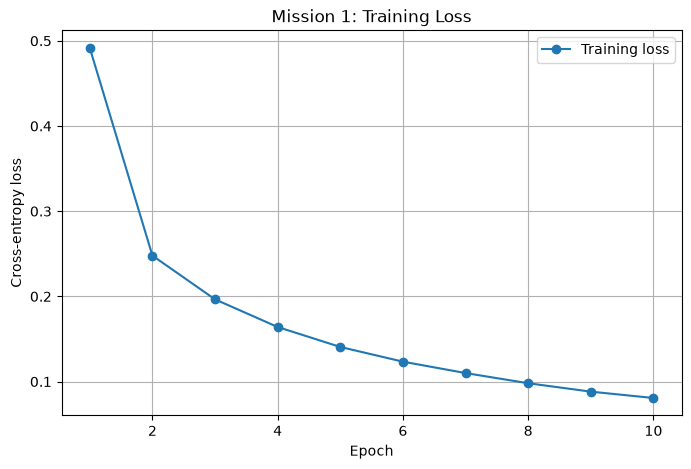

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(mission1_history["loss"]) + 1),
    mission1_history["loss"],
    marker="o",
    label="Training loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Mission 1: Training Loss")
plt.grid(True)
plt.legend()
plt.show()

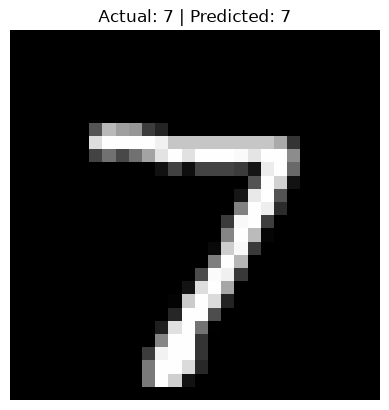

Correct prediction: True


In [11]:
index = 0

image = X_test[index]
true_label = y_test[index].item()

predicted_label = mission1_model.predict(
    image.unsqueeze(0)
)[0].item()

plt.imshow(image.reshape(28, 28), cmap="gray")
plt.title(
    f"Actual: {true_label} | Predicted: {predicted_label}"
)
plt.axis("off")
plt.show()

print("Correct prediction:", predicted_label == true_label)


In [12]:
experiments = [
    {
        "name": "Run 1 - Baseline",
        "sizes": (784, 128, 10),
        "activation": "relu",
        "lr": 0.05,
        "batch": 128,
        "lesson": "Baseline for comparison."
    },
    {
        "name": "Run 2 - Wider",
        "sizes": (784, 256, 10),
        "activation": "relu",
        "lr": 0.05,
        "batch": 128,
        "lesson": "More hidden neurons increase model capacity."
    },
    {
        "name": "Run 3 - Deeper",
        "sizes": (784, 256, 128, 10),
        "activation": "relu",
        "lr": 0.05,
        "batch": 128,
        "lesson": "An extra hidden layer can learn hierarchical features."
    },
    {
        "name": "Run 4 - Lower LR",
        "sizes": (784, 256, 128, 10),
        "activation": "relu",
        "lr": 0.01,
        "batch": 128,
        "lesson": "A smaller learning rate may improve stability."
    },
    {
        "name": "Run 5 - Batch 64",
        "sizes": (784, 256, 128, 10),
        "activation": "relu",
        "lr": 0.05,
        "batch": 64,
        "lesson": "Smaller batches produce more frequent updates."
    },
    {
        "name": "Run 6 - Tanh",
        "sizes": (784, 256, 128, 10),
        "activation": "tanh",
        "lr": 0.05,
        "batch": 128,
        "lesson": "Tanh is zero-centred but may saturate."
    }
]

In [13]:
experiment_results = []
mission2_histories = {}
mission2_models = {}

for run_number, exp in enumerate(experiments):

    print("\n" + "=" * 60)
    print(exp["name"])
    print("=" * 60)

    model, history = train_model(
        X_train, y_train, X_test, y_test,
        sizes=exp["sizes"],
        activation=exp["activation"],
        learning_rate=exp["lr"],
        batch_size=exp["batch"],
        epochs=15,
        seed=100 + run_number,
        run_name=exp["name"]
    )

    mission2_models[exp["name"]] = model
    mission2_histories[exp["name"]] = history

    experiment_results.append({
        "Run": exp["name"],
        "Architecture": str(exp["sizes"]),
        "Activation": exp["activation"],
        "Learning Rate": exp["lr"],
        "Batch Size": exp["batch"],
        "Epochs": 15,
        "Final Test Accuracy (%)":
            round(history["final_test_accuracy"], 2),
        "Epochs to 95%":
            history["epochs_to_95"],
        "Time (seconds)": round(history["seconds"], 1),
        "Lesson": exp["lesson"]
    })

mission2_df = pd.DataFrame(experiment_results)

display(mission2_df)


Run 1 - Baseline
Run 1 - Baseline | Epoch 01/15 | Loss: 0.5866 | Train Accuracy: 91.16% | Test Accuracy: 90.75%
Run 1 - Baseline | Epoch 02/15 | Loss: 0.3138 | Train Accuracy: 92.96% | Test Accuracy: 92.19%
Run 1 - Baseline | Epoch 03/15 | Loss: 0.2664 | Train Accuracy: 93.94% | Test Accuracy: 93.17%
Run 1 - Baseline | Epoch 04/15 | Loss: 0.2351 | Train Accuracy: 94.42% | Test Accuracy: 93.99%
Run 1 - Baseline | Epoch 05/15 | Loss: 0.2119 | Train Accuracy: 94.90% | Test Accuracy: 94.17%
Run 1 - Baseline | Epoch 06/15 | Loss: 0.1932 | Train Accuracy: 95.50% | Test Accuracy: 94.90%
Run 1 - Baseline | Epoch 07/15 | Loss: 0.1779 | Train Accuracy: 95.84% | Test Accuracy: 95.23%
Run 1 - Baseline | Epoch 08/15 | Loss: 0.1646 | Train Accuracy: 96.22% | Test Accuracy: 95.48%
Run 1 - Baseline | Epoch 09/15 | Loss: 0.1536 | Train Accuracy: 96.64% | Test Accuracy: 95.62%
Run 1 - Baseline | Epoch 10/15 | Loss: 0.1437 | Train Accuracy: 96.84% | Test Accuracy: 96.09%
Run 1 - Baseline | Epoch 11/15 |

,Run,Architecture,Activation,Learning Rate,Batch Size,Epochs,Final Test Accuracy (%),Epochs to 95%,Time (seconds),Lesson
0,Run 1 - Baseline,"(784, 128, 10)",relu,0.05,128,15,96.82,7,13.1,Baseline for comparison.
1,Run 2 - Wider,"(784, 256, 10)",relu,0.05,128,15,96.83,7,15.7,More hidden neurons increase model capacity.
2,Run 3 - Deeper,"(784, 256, 128, 10)",relu,0.05,128,15,97.47,4,29.5,An extra hidden layer can learn hierarchical f...
3,Run 4 - Lower LR,"(784, 256, 128, 10)",relu,0.01,128,15,95.12,15,27.2,A smaller learning rate may improve stability.
4,Run 5 - Batch 64,"(784, 256, 128, 10)",relu,0.05,64,15,97.81,2,46.6,Smaller batches produce more frequent updates.
5,Run 6 - Tanh,"(784, 256, 128, 10)",tanh,0.05,128,15,96.54,9,36.8,Tanh is zero-centred but may saturate.


In [14]:
output_dir = Path("ann_results")
output_dir.mkdir(exist_ok=True)

mission2_df.to_csv(
    output_dir / "mission2_experiment_log.csv",
    index=False
)

best_index = mission2_df[
    "Final Test Accuracy (%)"
].idxmax()

best_result = mission2_df.loc[best_index]

print("Best experiment:", best_result["Run"])
print("Best test accuracy:",
      best_result["Final Test Accuracy (%)"], "%")

if best_result["Final Test Accuracy (%)"] >= 97:
    print("SUCCESS: The 97% target was reached.")
else:
    print("The target was not reached. More tuning is required.")

display(mission2_df)

Best experiment: Run 5 - Batch 64
Best test accuracy: 97.81 %
SUCCESS: The 97% target was reached.


,Run,Architecture,Activation,Learning Rate,Batch Size,Epochs,Final Test Accuracy (%),Epochs to 95%,Time (seconds),Lesson
0,Run 1 - Baseline,"(784, 128, 10)",relu,0.05,128,15,96.82,7,13.1,Baseline for comparison.
1,Run 2 - Wider,"(784, 256, 10)",relu,0.05,128,15,96.83,7,15.7,More hidden neurons increase model capacity.
2,Run 3 - Deeper,"(784, 256, 128, 10)",relu,0.05,128,15,97.47,4,29.5,An extra hidden layer can learn hierarchical f...
3,Run 4 - Lower LR,"(784, 256, 128, 10)",relu,0.01,128,15,95.12,15,27.2,A smaller learning rate may improve stability.
4,Run 5 - Batch 64,"(784, 256, 128, 10)",relu,0.05,64,15,97.81,2,46.6,Smaller batches produce more frequent updates.
5,Run 6 - Tanh,"(784, 256, 128, 10)",tanh,0.05,128,15,96.54,9,36.8,Tanh is zero-centred but may saturate.


In [15]:
activation_histories = {}
activation_models = {}

for activation in ["relu", "sigmoid", "tanh"]:

    print("\nTraining with:", activation)

    model, history = train_model(
        X_train, y_train, X_test, y_test,
        sizes=(784, 128, 64, 10),
        activation=activation,
        learning_rate=0.05,
        batch_size=128,
        epochs=15,
        seed=300,
        run_name=f"Mission 3 - {activation}"
    )

    activation_models[activation] = model
    activation_histories[activation] = history


Training with: relu
Mission 3 - relu | Epoch 01/15 | Loss: 0.5306 | Train Accuracy: 92.08% | Test Accuracy: 91.47%
Mission 3 - relu | Epoch 02/15 | Loss: 0.2582 | Train Accuracy: 93.88% | Test Accuracy: 93.00%
Mission 3 - relu | Epoch 03/15 | Loss: 0.2067 | Train Accuracy: 95.24% | Test Accuracy: 94.52%
Mission 3 - relu | Epoch 04/15 | Loss: 0.1739 | Train Accuracy: 96.26% | Test Accuracy: 95.19%
Mission 3 - relu | Epoch 05/15 | Loss: 0.1512 | Train Accuracy: 96.80% | Test Accuracy: 95.90%
Mission 3 - relu | Epoch 06/15 | Loss: 0.1338 | Train Accuracy: 96.86% | Test Accuracy: 95.73%
Mission 3 - relu | Epoch 07/15 | Loss: 0.1206 | Train Accuracy: 97.42% | Test Accuracy: 96.45%
Mission 3 - relu | Epoch 08/15 | Loss: 0.1091 | Train Accuracy: 97.58% | Test Accuracy: 96.55%
Mission 3 - relu | Epoch 09/15 | Loss: 0.0993 | Train Accuracy: 97.94% | Test Accuracy: 96.93%
Mission 3 - relu | Epoch 10/15 | Loss: 0.0910 | Train Accuracy: 97.78% | Test Accuracy: 96.91%
Mission 3 - relu | Epoch 11/1

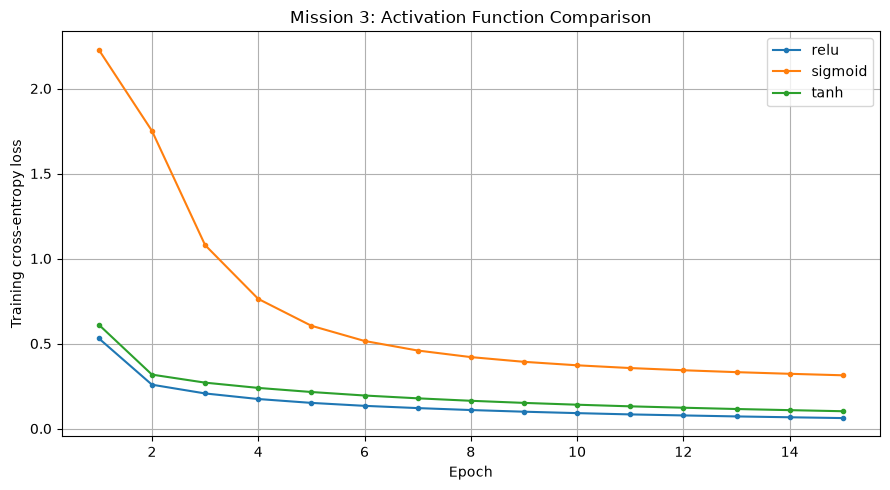

In [16]:
plt.figure(figsize=(9, 5))

for activation, history in activation_histories.items():
    plt.plot(
        range(1, len(history["loss"]) + 1),
        history["loss"],
        marker=".",
        label=activation
    )

plt.xlabel("Epoch")
plt.ylabel("Training cross-entropy loss")
plt.title("Mission 3: Activation Function Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    output_dir / "mission3_loss.png",
    dpi=160
)

plt.show()

In [17]:
activation_results = []

for activation, history in activation_histories.items():

    epoch_95 = history["epochs_to_95"]

    activation_results.append({
        "Activation": activation,
        "Final Test Accuracy (%)": round(
            history["final_test_accuracy"], 2
        ),
        "Epochs to Reach 95%": (
            epoch_95 if epoch_95 is not None
            else "Not reached"
        )
    })

activation_df = pd.DataFrame(activation_results)
display(activation_df)

activation_df.to_csv(
    output_dir / "mission3_activation_results.csv",
    index=False
)

,Activation,Final Test Accuracy (%),Epochs to Reach 95%
0,relu,97.29,4
1,sigmoid,91.30,Not reached
2,tanh,96.57,7


In [18]:
def gradient_check(model, X, y, epsilon=1e-5):

    # Use double precision for the numerical calculation.
    model.W = [w.detach().double() for w in model.W]
    model.b = [b.detach().double() for b in model.b]

    x = X[:8].to(device=device, dtype=torch.float64)
    targets = y[:8].to(device)

    # Calculate analytical gradients.
    logits, activations, preactivations = model.forward(x)
    loss = model.loss_fn(logits, targets)

    model.zero_grad()
    model.backward(targets, activations, preactivations)

    print("Original loss:", loss.item())

    errors = []

    with torch.no_grad():

        # Check one weight in every layer.
        for layer in range(len(model.W)):

            r = 0
            c = 0

            original_weight = model.W[layer][r, c].item()
            analytical = model.dW[layer][r, c].item()

            # L(w + epsilon)
            model.W[layer][r, c] = original_weight + epsilon

            plus_logits, _, _ = model.forward(x)
            plus_loss = model.loss_fn(
                plus_logits, targets
            ).item()

            # L(w - epsilon)
            model.W[layer][r, c] = original_weight - epsilon

            minus_logits, _, _ = model.forward(x)
            minus_loss = model.loss_fn(
                minus_logits, targets
            ).item()

            # Restore the original weight.
            model.W[layer][r, c] = original_weight

            numerical = (
                plus_loss - minus_loss
            ) / (2 * epsilon)

            relative_error = abs(
                analytical - numerical
            ) / max(
                1e-12,
                abs(analytical) + abs(numerical)
            )

            errors.append(relative_error)

            print(f"\nLayer {layer + 1}")
            print(f"Analytical gradient: {analytical:.10e}")
            print(f"Numerical gradient:  {numerical:.10e}")
            print(f"Relative error:      {relative_error:.10e}")

    max_error = max(errors)

    print("\nMaximum relative error:", max_error)
    print("All checks below 1e-5:", max_error < 1e-5)

    return max_error

In [19]:
relu_model = activation_models["relu"]

max_gradient_error = gradient_check(
    relu_model,
    X_train,
    y_train,
    epsilon=1e-5
)

Original loss: 0.01665215287136969

Layer 1
Analytical gradient: 0.0000000000e+00
Numerical gradient:  0.0000000000e+00
Relative error:      0.0000000000e+00

Layer 2
Analytical gradient: -2.2536954556e-03
Numerical gradient:  -2.2536954563e-03
Relative error:      1.5080499914e-10

Layer 3
Analytical gradient: -1.4015525028e-06
Numerical gradient:  -1.4015557812e-06
Relative error:      1.1695353140e-06

Maximum relative error: 1.16953531404884e-06
All checks below 1e-5: True


In [21]:
def first_layer_mean_gradient(model, X, y):

    x = X[:256].to(device=device, dtype=model.W[0].dtype)
    targets = y[:256].to(device=device, dtype=torch.long)

    logits, activations, preactivations = model.forward(x)

    model.zero_grad()
    model.backward(
        targets,
        activations,
        preactivations
    )

    return model.dW[0].abs().mean().item()


gradient_results = []
for activation, model in activation_models.items():

    mean_gradient = first_layer_mean_gradient(
        model, X_train, y_train
    )

    gradient_results.append({
        "Activation": activation,
        "Mean Absolute First-Layer Weight Gradient":
            mean_gradient
    })

gradient_df = pd.DataFrame(gradient_results)
display(gradient_df)

gradient_df.to_csv(
    output_dir / "mission3_gradient_results.csv",
    index=False
)

,Activation,Mean Absolute First-Layer Weight Gradient
0,relu,0.000571
1,sigmoid,0.000204
2,tanh,0.000453


In [22]:
X_test_rotated = torch.stack([
    transforms.functional.rotate(
        image.view(1, 28, 28),
        angle=15,
        interpolation=transforms.InterpolationMode.BILINEAR
    ).reshape(784)
    for image in X_test
])

print("Original test shape:", X_test.shape)
print("Rotated test shape:", X_test_rotated.shape)

Original test shape: torch.Size([10000, 784])
Rotated test shape: torch.Size([10000, 784])


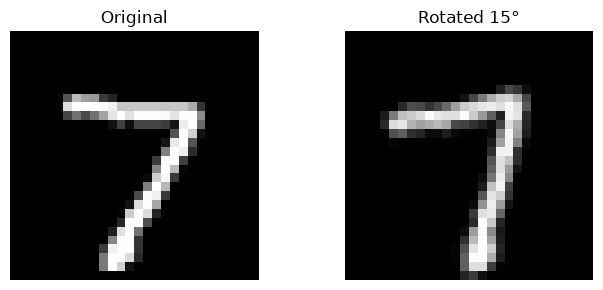

In [23]:
index = 0

plt.figure(figsize=(7, 3))

plt.subplot(1, 2, 1)
plt.imshow(X_test[index].reshape(28, 28), cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(X_test_rotated[index].reshape(28, 28), cmap="gray")
plt.title("Rotated 15°")
plt.axis("off")

plt.tight_layout()
plt.show()

In [24]:
# Retrieve the configuration of the measured best Mission 2 run.
best_exp = next(
    exp for exp in experiments
    if exp["name"] == best_result["Run"]
)

best_sizes = best_exp["sizes"]
best_activation = best_exp["activation"]
best_lr = best_exp["lr"]
best_batch = best_exp["batch"]

print("Selected configuration:", best_exp)

# Train a clean-data reference model.
clean_model, clean_history = train_model(
    X_train, y_train, X_test, y_test,
    sizes=best_sizes,
    activation=best_activation,
    learning_rate=best_lr,
    batch_size=best_batch,
    epochs=15,
    seed=500,
    run_name="Mission 4 - Clean"
)

# Train a model with noise applied to 20% of training images.
noisy_model, noisy_history = train_model(
    X_train, y_train, X_test, y_test,
    sizes=best_sizes,
    activation=best_activation,
    learning_rate=best_lr,
    batch_size=best_batch,
    epochs=15,
    seed=500,
    noisy_fraction=0.20,
    noise_std=0.3,
    run_name="Mission 4 - Noisy"
)

Selected configuration: {'name': 'Run 5 - Batch 64', 'sizes': (784, 256, 128, 10), 'activation': 'relu', 'lr': 0.05, 'batch': 64, 'lesson': 'Smaller batches produce more frequent updates.'}
Mission 4 - Clean | Epoch 01/15 | Loss: 0.3892 | Train Accuracy: 94.10% | Test Accuracy: 93.10%
Mission 4 - Clean | Epoch 02/15 | Loss: 0.1930 | Train Accuracy: 96.24% | Test Accuracy: 95.25%
Mission 4 - Clean | Epoch 03/15 | Loss: 0.1426 | Train Accuracy: 96.92% | Test Accuracy: 96.12%
Mission 4 - Clean | Epoch 04/15 | Loss: 0.1129 | Train Accuracy: 97.78% | Test Accuracy: 96.66%
Mission 4 - Clean | Epoch 05/15 | Loss: 0.0933 | Train Accuracy: 97.40% | Test Accuracy: 96.22%
Mission 4 - Clean | Epoch 06/15 | Loss: 0.0785 | Train Accuracy: 98.32% | Test Accuracy: 97.02%
Mission 4 - Clean | Epoch 07/15 | Loss: 0.0671 | Train Accuracy: 98.70% | Test Accuracy: 97.39%
Mission 4 - Clean | Epoch 08/15 | Loss: 0.0579 | Train Accuracy: 98.94% | Test Accuracy: 97.49%
Mission 4 - Clean | Epoch 09/15 | Loss: 0.

In [25]:
results_m4 = []

models_to_test = {
    "Clean-trained": clean_model,
    "Noisy-trained": noisy_model
}

for model_name, model in models_to_test.items():

    clean_accuracy = model.accuracy(X_test, y_test)

    rotated_accuracy = model.accuracy(
        X_test_rotated, y_test
    )

    accuracy_drop = clean_accuracy - rotated_accuracy

    results_m4.append({
        "Model": model_name,
        "Clean Test Accuracy (%)": round(clean_accuracy, 2),
        "Rotated Test Accuracy (%)": round(rotated_accuracy, 2),
        "Rotation Accuracy Drop (percentage points)":
            round(accuracy_drop, 2)
    })

mission4_df = pd.DataFrame(results_m4)
display(mission4_df)

,Model,Clean Test Accuracy (%),Rotated Test Accuracy (%),Rotation Accuracy Drop (percentage points)
0,Clean-trained,97.61,93.52,4.09
1,Noisy-trained,97.86,94.05,3.81


In [26]:
robust_model, robust_history = train_model(
    X_train, y_train, X_test, y_test,
    sizes=best_sizes,
    activation=best_activation,
    learning_rate=best_lr,
    batch_size=best_batch,
    epochs=15,
    seed=501,
    noisy_fraction=0.20,
    noise_std=0.3,
    rotation_augmentation=True,
    run_name="Mission 4 - Defence"
)

robust_clean_accuracy = robust_model.accuracy(
    X_test, y_test
)

robust_rotated_accuracy = robust_model.accuracy(
    X_test_rotated, y_test
)

print(f"Defence model, clean accuracy: "
      f"{robust_clean_accuracy:.2f}%")

print(f"Defence model, rotated accuracy: "
      f"{robust_rotated_accuracy:.2f}%")

Mission 4 - Defence | Epoch 01/15 | Loss: 0.4736 | Train Accuracy: 93.48% | Test Accuracy: 92.95%
Mission 4 - Defence | Epoch 02/15 | Loss: 0.2487 | Train Accuracy: 95.72% | Test Accuracy: 95.08%
Mission 4 - Defence | Epoch 03/15 | Loss: 0.1916 | Train Accuracy: 96.38% | Test Accuracy: 95.81%
Mission 4 - Defence | Epoch 04/15 | Loss: 0.1589 | Train Accuracy: 96.54% | Test Accuracy: 95.70%
Mission 4 - Defence | Epoch 05/15 | Loss: 0.1370 | Train Accuracy: 97.44% | Test Accuracy: 96.93%
Mission 4 - Defence | Epoch 06/15 | Loss: 0.1219 | Train Accuracy: 97.42% | Test Accuracy: 96.89%
Mission 4 - Defence | Epoch 07/15 | Loss: 0.1112 | Train Accuracy: 97.88% | Test Accuracy: 97.22%
Mission 4 - Defence | Epoch 08/15 | Loss: 0.1038 | Train Accuracy: 98.24% | Test Accuracy: 97.54%
Mission 4 - Defence | Epoch 09/15 | Loss: 0.0952 | Train Accuracy: 98.32% | Test Accuracy: 97.67%
Mission 4 - Defence | Epoch 10/15 | Loss: 0.0878 | Train Accuracy: 98.46% | Test Accuracy: 97.74%
Mission 4 - Defence 

In [27]:
# Save Mission 1 epoch-by-epoch results.
mission1_df = pd.DataFrame({
    "Epoch": range(1, len(mission1_history["loss"]) + 1),
    "Training Loss": mission1_history["loss"],
    "Training Accuracy (%)": mission1_history["train_accuracy"],
    "Test Accuracy (%)": mission1_history["test_accuracy"]
})

mission1_df.to_csv(
    output_dir / "mission1_training_log.csv",
    index=False
)

# Save Mission 4 comparison, including the defence model.
final_m4_results = []

for name, model in [
    ("Clean-trained", clean_model),
    ("Noisy-trained", noisy_model),
    ("Noise + rotation augmentation", robust_model)
]:
    clean_acc = model.accuracy(X_test, y_test)
    rotated_acc = model.accuracy(X_test_rotated, y_test)

    final_m4_results.append({
        "Model": name,
        "Clean Test Accuracy (%)": round(clean_acc, 2),
        "Rotated Test Accuracy (%)": round(rotated_acc, 2),
        "Rotation Drop (percentage points)": round(
            clean_acc - rotated_acc, 2
        )
    })

final_m4_df = pd.DataFrame(final_m4_results)

final_m4_df.to_csv(
    output_dir / "mission4_results.csv",
    index=False
)

# Save the final comparison as a readable text report.
with open(output_dir / "mission4_results.txt", "w") as file:
    file.write("MISSION 4: ROBUSTNESS RESULTS\n\n")
    file.write(final_m4_df.to_string(index=False))

print("Saved all results to:", output_dir.resolve())

print("\nFiles created:")
for file in sorted(output_dir.iterdir()):
    print("-", file.name)

Saved all results to: D:\DeepLearning\ann_results

Files created:
- mission1_training_log.csv
- mission2_experiment_log.csv
- mission3_activation_results.csv
- mission3_gradient_results.csv
- mission3_loss.png
- mission4_results.csv
- mission4_results.txt


In [28]:
print("MISSION 1")
print("Final test accuracy:",
      f"{mission1_history['final_test_accuracy']:.2f}%")

print("\nMISSION 2")
print("Best run:", best_result["Run"])
print("Best accuracy:",
      f"{best_result['Final Test Accuracy (%)']:.2f}%")
print("97% target met:",
      best_result["Final Test Accuracy (%)"] >= 97)

print("\nMISSION 3")
print("Gradient check maximum error:",
      f"{max_gradient_error:.3e}")
print("Gradient threshold met:",
      max_gradient_error < 1e-5)

print("\nMISSION 4")
display(final_m4_df)

MISSION 1
Final test accuracy: 96.81%

MISSION 2
Best run: Run 5 - Batch 64
Best accuracy: 97.81%
97% target met: True

MISSION 3
Gradient check maximum error: 1.170e-06
Gradient threshold met: True

MISSION 4


,Model,Clean Test Accuracy (%),Rotated Test Accuracy (%),Rotation Drop (percentage points)
0,Clean-trained,97.61,93.52,4.09
1,Noisy-trained,97.86,94.05,3.81
2,Noise + rotation augmentation,97.44,95.66,1.78
